# 05-03 - Fine-Tuning

You train the lecture's network yourself, a new decoder on the frozen encoder, on 24 chips and on your own processor, and watch the curve the lecture only showed.

We start with the lecture's four runs and the bar the frozen run set on the block. Then we look at the 24 chips, replace the decoder by a fresh one, train it for twelve epochs, draw your curve beside the lecture's, and turn one chip eight ways. At the end you train on eight chips.

Before you run anything, choose *File*, then *Save As*, and give the copy a name with `-mywork` in it, so that the next pull never collides with your work.

In [1]:
import json

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seg_tools as seg

plt.rcParams["figure.dpi"] = 72

scene = seg.load_scene("data/scene.json")
reference = json.load(open("data/ground_truth.json"))["p05"]
torch_ok = seg.torch_available()
print(f"the window of {scene['window']['date']}: {scene['window']['pixels']:,} pixels a side at "
      f"{scene['window']['resolution_m']} m, {scene['blocks']['n']} blocks, "
      f"{scene['chips']['tiled']['total']:,} chips; the deep learning library is "
      f"{'ready' if torch_ok else 'missing, so the cells that need it are skipped'}")

the window of 2023-08-20: 10,240 pixels a side at 0.3 m, 25 blocks, 1,600 chips; the deep learning library is ready


## Four runs, one recipe

The cell reads the lecture's training curves and draws the validation IoU of the four U-Net runs per epoch, with the kept epoch marked.

encoder fine-tuned kept epoch 24, test chips IoU 0.663, 12,460,881 weights moved
encoder frozen     kept epoch 18, test chips IoU 0.592, 1,284,369 weights moved
from scratch       kept epoch 30, test chips IoU 0.625, 12,460,881 weights moved
without skips      kept epoch 25, test chips IoU 0.626, 12,064,593 weights moved
the frozen run on this block 0.707, the fine-tuned run 0.744


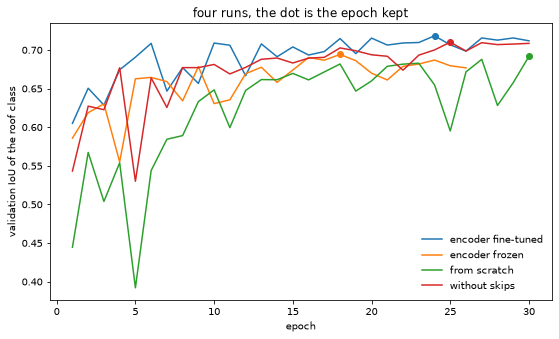

In [2]:
curves = seg.read_curves("data/curves.json")
names = {"main": "encoder fine-tuned", "frozen": "encoder frozen", "scratch": "from scratch",
         "noskip": "without skips"}
runs = {k: curves["unet"][k] for k in names}
for k, run in runs.items():
    print(f"{names[k]:18} kept epoch {run['best_epoch']:2d}, test chips IoU {run['test_iou']:.3f}, "
          f"{run['trainable']:,} weights moved")
print(f"the frozen run on this block {reference['block']['frozen']['iou']:.3f}, "
      f"the fine-tuned run {reference['block']['finetuned']['iou']:.3f}")
fig, ax = plt.subplots(figsize=(9, 5))
seg.show_curves(ax, runs, 4, names, "validation IoU of the roof class",
                "four runs, the dot is the epoch kept")

Every run is the same loop, batches of 8 chips, the eight symmetries, Adam, early stopping on the four validation blocks, and each differs from the main run in one thing. Frozen keeps the ImageNet encoder and moves only the decoder's 1.3 million weights. Scratch starts the encoder at random. Without skips cuts the rungs of the U. Read the kept epochs and the scores. The frozen run is the one whose weights the kit ships, and its score on this block is the bar you train against.

## Twenty-four training chips

The cell reads the 24 training chips and their masks, cuts sixteen evaluation chips from the test block, and draws the first eight training chips.

24 chips from blocks [3, 4, 6, 8, 9, 11, 16, 17], roof shares 11% to 19%
the lecture trained on 3,600 overlapping chips


16 evaluation chips cut from the test block, never trained on


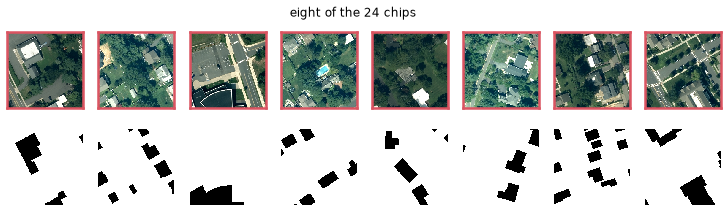

In [3]:
T = seg.read_npz("data/train_chips.npz")
print(f"{len(T['images'])} chips from blocks {sorted(set(T['block'].tolist()))}, "
      f"roof shares {T['share'].min():.0%} to {T['share'].max():.0%}")
print(f"the lecture trained on {scene['chips']['overlapping']['train']:,} overlapping chips")
image, transform, crs, res = seg.read_raster("data/block_7.tif")
mask, *_ = seg.read_raster("data/mask_7.tif")
here = seg.block_chips(seg.chip_table("data/chips.csv"), scene["block"]["id"])
origin = (here["row"].min(), here["col"].min())
ev_images, ev_masks = seg.cut_chips(image, mask, here["row"][:16], here["col"][:16], origin=origin)
print(f"{len(ev_images)} evaluation chips cut from the test block, never trained on")
fig = seg.show_chips(T["images"][:8], T["masks"][:8], labels=[True] * 8, title="eight of the 24 chips")

The lecture had 3,600 overlapping chips of sixteen blocks. You have 24, three from each of the eight training blocks with the most roof, each with between a tenth and a fifth of its pixels under a roof. A project can draw that many in an afternoon, and the question is what it buys. Look at the masks. They are the volunteers' footprints, which is what the decoder will be asked to paint, sharp corners and all. The sixteen evaluation chips come from the test block, which training never sees.

## A fresh decoder on the frozen encoder

The cell loads the shipped model, replaces its decoder by a fresh one, and predicts one evaluation chip before any training.

1,284,369 decoder weights start from random, the encoder stays


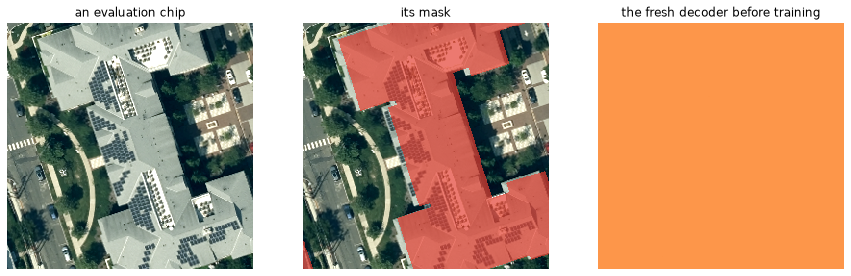

In [4]:
if torch_ok:
    model, provenance = seg.load_model("data/segmenter_frozen.npz")
    fresh = seg.fresh_decoder(model, seed=scene["seed"])
    before = seg.predict(fresh, ev_images[:1])[0]
    print(f"{seg.count_parameters(fresh)['decoder']:,} decoder weights start from random, the encoder stays")
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    seg.show_image(axes[0], seg.stretch(ev_images[0]), "an evaluation chip")
    seg.show_mask(axes[1], seg.stretch(ev_images[0]), ev_masks[0] > 0, "its mask")
    seg.show_image(axes[2], before, "the fresh decoder before training", cmap="Oranges", vmin=0, vmax=1)
else:
    print(seg.NO_TORCH)

The decoder's weights are re-drawn from a seed, so its first answer is noise around one half everywhere, as the third picture shows. The encoder keeps its ImageNet weights and will not move, which is the frozen recipe of the lecture. Everything the decoder learns in the next cell it learns from 24 chips, and nothing from the sixteen it is scored on.

## Twelve epochs on the processor

The cell trains the fresh decoder on the 24 chips for twelve epochs in batches of four, scores the sixteen evaluation chips after each, then the whole block.

epoch  1   training loss 0.701   IoU on the evaluation chips 0.171   0.6 s
epoch  2   training loss 0.612   IoU on the evaluation chips 0.212   0.2 s


epoch  3   training loss 0.553   IoU on the evaluation chips 0.254   0.2 s


epoch  4   training loss 0.522   IoU on the evaluation chips 0.334   0.2 s


epoch  5   training loss 0.498   IoU on the evaluation chips 0.329   0.2 s


epoch  6   training loss 0.477   IoU on the evaluation chips 0.378   0.2 s


...

epoch  8   training loss 0.439   IoU on the evaluation chips 0.399   0.2 s


epoch  9   training loss 0.420   IoU on the evaluation chips 0.397   0.2 s
epoch 10   training loss 0.404   IoU on the evaluation chips 0.384   0.2 s


epoch 11   training loss 0.389   IoU on the evaluation chips 0.374   0.2 s


epoch 12   training loss 0.377   IoU on the evaluation chips 0.300   0.2 s


64 chips predicted in 1 s on mps
the whole block after 12 epochs on 24 chips: IoU 0.424; the lecture's frozen run 0.707 on 3,600 chips


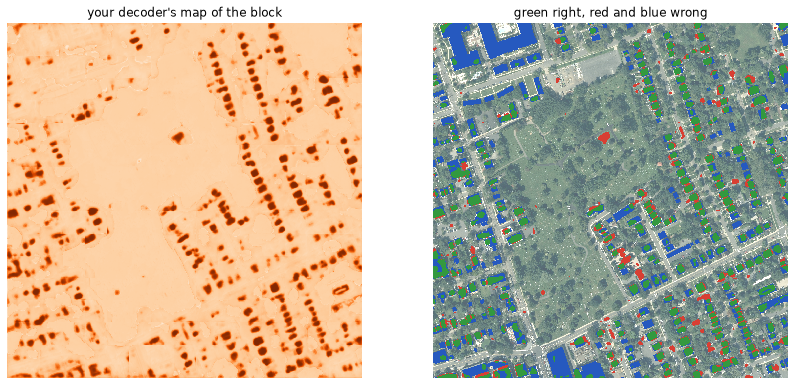

In [5]:
if torch_ok:
    EPOCHS = 12
    trained, curve = seg.train_decoder(fresh, T["images"], T["masks"], epochs=EPOCHS, batch=4,
                                       eval_chips=ev_images, eval_masks=ev_masks)
    own = seg.predict_block(trained, image)
    print(f"the whole block after {EPOCHS} epochs on {len(T['images'])} chips: IoU "
          f"{seg.iou(own >= 0.5, mask > 0):.3f}; the lecture's frozen run "
          f"{reference['block']['frozen']['iou']:.3f} on 3,600 chips")
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    seg.show_image(axes[0], own, "your decoder's map of the block", cmap="Oranges", vmin=0, vmax=1)
    seg.show_agreement(axes[1], own >= 0.5, mask > 0, seg.stretch(image), "green right, red and blue wrong")
else:
    print(seg.NO_TORCH)

The loss falls from the coin toss and the IoU on the evaluation chips climbs from nothing within a few epochs, then wobbles, because 24 chips in batches of four are six steps an epoch and every step is a small, noisy push. On a laptop's processor the run takes a minute or two. The last line scores all 64 chips of the block against the lecture's frozen run, which had 150 times the chips. On the map the roofs are there, the edges soft, the trees where it hesitates.

## Your curve beside the lecture's

The cell draws your training loss and your evaluation IoU per epoch beside the lecture's frozen run.

your last loss 0.377; the lecture's run reached 0.694 on its validation chips at epoch 18


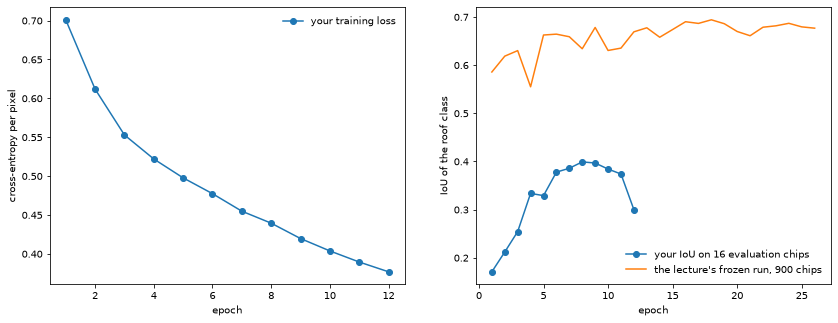

In [6]:
if torch_ok:
    rows = np.array(curve)
    lecture_frozen = np.array(curves["unet"]["frozen"]["curve"])
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(rows[:, 0], rows[:, 1], marker="o", label="your training loss")
    axes[0].set(xlabel="epoch", ylabel="cross-entropy per pixel")
    axes[1].plot(rows[:, 0], rows[:, 2], marker="o", label="your IoU on 16 evaluation chips")
    axes[1].plot(lecture_frozen[:, 0], lecture_frozen[:, 4], label="the lecture's frozen run, 900 chips")
    axes[1].set(xlabel="epoch", ylabel="IoU of the roof class")
    for ax in axes:
        ax.legend(frameon=False)
    print(f"your last loss {rows[-1, 1]:.3f}; the lecture's run reached {lecture_frozen[:, 4].max():.3f} "
          f"on its validation chips at epoch {int(curves['unet']['frozen']['best_epoch'])}")
else:
    print(seg.NO_TORCH)

Two curves of the same kind on very different diets. Your loss falls fast because there is little to fit, and your IoU jumps about because sixteen chips are a noisy referee, the reason the lecture kept four whole blocks for validation. The lecture's curve climbs for eighteen epochs on 900 chips before its referee says stop. Early stopping on your curve would be a coin toss; on the lecture's it is a decision. More chips buy a smoother curve before they buy a higher one.

## Eight views of one chip

The cell turns one training chip and its mask through the four quarter turns and their mirrors.

the lecture's chip classifier with the eight symmetries 91.9%, without 91.6% on the test blocks


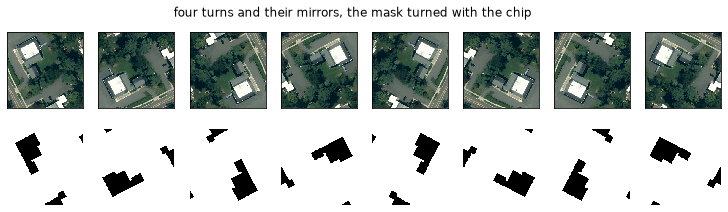

In [7]:
views = [seg.dihedral(T["images"][0], T["masks"][0], k % 4, k >= 4) for k in range(8)]
fig = seg.show_chips([v[0] for v in views], [v[1] for v in views], ncols=8,
                     title="four turns and their mirrors, the mask turned with the chip")
clf = reference["lecture"]["classifier"]
print(f"the lecture's chip classifier with the eight symmetries {clf['finetuned']['test_acc']:.1%}, "
      f"without {clf['finetuned_noaug']['test_acc']:.1%} on the test blocks")

A picture taken straight down has no up, so every turn and mirror of a chip is another valid picture of Princeton, and the mask turned with it is still its mask. The training cell above used them: each chip of each batch entered in one of these eight views at random, so 24 chips were 192 pictures. The lecture's numbers in the printed line say what the symmetries bought the chip classifier. At street level only the mirror is legal, because cars do not drive on the sky.

## Your turn

Train again on a third of the chips. The cell runs the same recipe on the first N_CHIPS chips and scores the block. Run the cell as it is, then change the marked value and run it again.

How much did the block's IoU change between 24 and 8 chips, and what does that say about the labels a project needs? Write your answer in one or two sentences. The answer comes in Friday's post, not in the kit.

In [8]:
N_CHIPS = 24  # change me: 8
if torch_ok:
    again, curve2 = seg.train_decoder(fresh, T["images"][:N_CHIPS], T["masks"][:N_CHIPS], epochs=12,
                                      batch=4, eval_chips=ev_images, eval_masks=ev_masks, quiet=True)
    own2 = seg.predict_block(again, image, quiet=True)
    print(f"{N_CHIPS} chips, 12 epochs: IoU on the block {seg.iou(own2 >= 0.5, mask > 0):.3f}")
else:
    print(seg.NO_TORCH)

24 chips, 12 epochs: IoU on the block 0.424


## Check your understanding

1. Why does the decoder learn anything at all from 24 chips, and what part of the network is doing most of the work?
2. Your IoU on sixteen chips jumped from epoch to epoch. Why did the lecture keep four whole blocks to decide when to stop?
3. The frozen run kept its encoder's ImageNet weights and still scored 0.59 on the lecture's test chips. What did fine-tuning the encoder add, and at what cost in time?
4. Which of the eight symmetries are legal for a street photograph, and why?

## Where we are

You have trained a decoder on 24 chips on your own processor, watched its loss and its IoU epoch by epoch, scored it on the block against the lecture's run, and seen the eight views augmentation makes of one chip. You now know what a few labels buy on a pretrained body, and why a training curve needs a steady referee. In 05-04 the same recipe looks at a street from the pavement.

## Further resources

Nothing in this course requires anything below.

- Understanding Deep Learning, chapter 6 on fitting and chapter 9 on regularisation, Simon Prince, MIT Press, 2023, https://udlbook.github.io/udlbook/
- Deep Learning, Foundations and Concepts, chapter 7 on gradient descent and chapter 9 on regularisation, Christopher Bishop and Hugh Bishop, Springer, 2024
- Hands-On Machine Learning with Scikit-Learn and PyTorch, chapter 11 on reusing pretrained layers, Aurélien Géron, O'Reilly, 2025

The model, its weights, its outputs and this kit are the course's own work, published under CC BY 4.0. The imagery is NAIP 2023 of the USDA, public domain, read from the Planetary Computer. The footprints are an OpenStreetMap extract, licensed ODbL 1.0, copyright OpenStreetMap contributors: https://www.openstreetmap.org/copyright